# Settings

In [ ]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/hair_data/0005_params.json"
#Simulation settings
using_simulation_data = False
bf_matrix_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/phantom_test/beamformed_apodized/0001_bf_rectangle.npy"

#Real data settings
using_matlab_data = True
matlab_bf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data/002_test/0005_BM.mat"
interpolate_data = True

#Saving params
save_data = True
save_image = True
bf_data_path = "./data_filtered/"
folder_name = "hair_data"
beamformed_filtered_matrix_name = "0001_bff"

# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import json
import os
from scipy.signal import butter, lfilter
from scipy.io import loadmat

# Import parameters

In [3]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [4]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [ ]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.01261568 m


# Create workspace

In [6]:
if not os.path.exists(f"{bf_data_path}{folder_name}"):
    os.makedirs(f"{bf_data_path}{folder_name}")
    print(f"Folder {bf_data_path}{folder_name} doesn't exist. Setting up the folder.")

os.makedirs(f"{bf_data_path}{folder_name}/filtered_bf", exist_ok=True)
os.makedirs(f"{bf_data_path}{folder_name}/images", exist_ok=True)

# Import BF matrix

In [7]:
if using_simulation_data:
    
    bf_matrix = np.load(bf_matrix_path)
    print("Imported bf matrix with shape: ", bf_matrix.shape)

else:
    if using_matlab_data:
        bf_matrix = loadmat(matlab_bf_data_path)
        bf_matrix = list(bf_matrix.values())[-1]
        if bf_matrix.ndim == 4:
            np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], bf_matrix.shape[2] * bf_matrix.shape[3]))
        print("Imported bf matrix with shape: ", bf_matrix.shape)
    else:
        bf_matrix = np.load(bf_matrix_path)
        print("Imported bf matrix with shape: ", bf_matrix.shape)


if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]


Imported bf matrix with shape:  (267, 256, 1, 20)


In [8]:
bf_matrix = np.reshape(bf_matrix, (bf_matrix.shape[0], bf_matrix.shape[1], 20))
bf_matrix = np.real(bf_matrix)

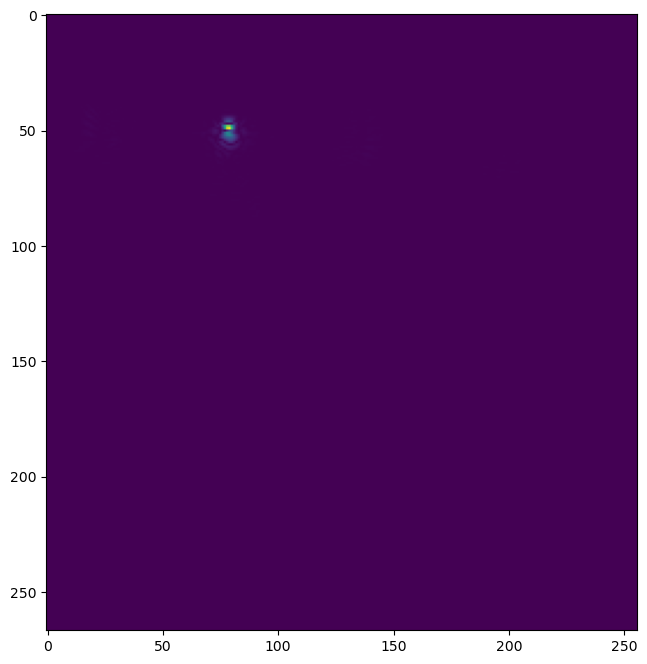

In [9]:
pixel_width = params["image"]["dx"]
pixel_height = params["image"]["dz"]
physical_aspect = pixel_width / pixel_height

plt.figure(figsize=(10, 8))
plt.imshow(np.abs(np.sum(bf_matrix, axis=2)), cmap='viridis', aspect=physical_aspect,
        #    extent=[0, samples_for_array_length * pixel_width, #for unit 
        #            samples_for_acquisition_depth * pixel_height, 0]
        )

Text(0.5, 0, 'Depth (samples)')

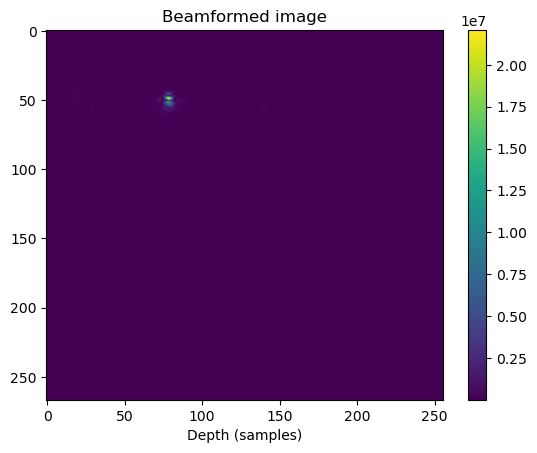

In [10]:

plt.imshow(np.abs(np.sum(bf_matrix, axis=2)), aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("Beamformed image")
plt.xlabel("Depth (samples)")

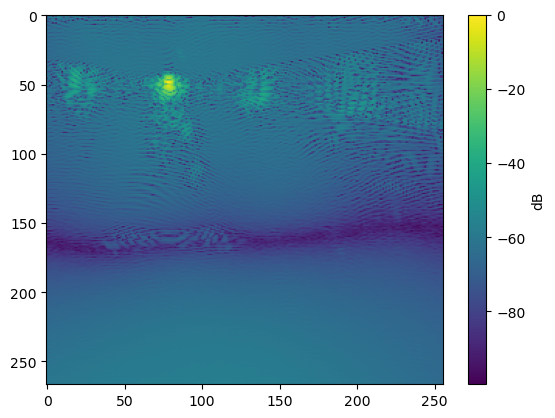

In [11]:
plt.imshow(20 * np.log10(np.sum(np.abs(bf_matrix), axis=2) / np.max(np.sum(np.abs(bf_matrix), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.show()

# Save data

In [12]:
def save_beamformed_data(bf_matrix, filename, destination):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

# Filters

## SVD

In [13]:
def filter_svd(bf, nelim):
    if nelim == 0:
        return bf, None
    #get dimensions of data
    nz, nx, nt = bf.shape
    #reshape to 2D matrix (space-time)
    m = np.reshape(bf, (nz*nx, nt))
    #remove mean from each row
    m = m - np.mean(m, axis=1, keepdims=True)
    #perform SVD decomposition
    U, S, Vt = np.linalg.svd(m, full_matrices=False)
    #create diagonal matrix from singular values
    Sf = np.diag(S)
    #set smallest singular values to zero (eliminating noise)
    Sf[:nelim, :nelim] = 0
    #reconstruct filtered matrix 
    mf = U @ Sf @ Vt
    #reshape back to 3D
    bff = np.reshape(mf, (nz, nx, nt))
    #return filtered data and singular values
    return bff, S

Beamformed data of shape (267, 256) saved at: ./data_filtered/hair_data/filtered_bf/0001_bff_svd.npy


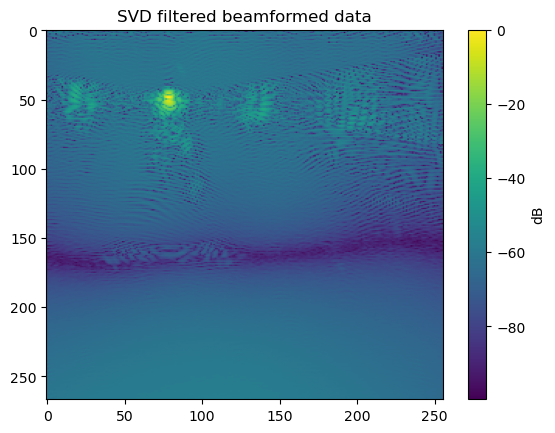

In [14]:
filtered_svd, S = filter_svd(bf_matrix, 0)
plt.imshow(20 * np.log10(np.sum(np.abs(filtered_svd),axis=2) / np.max(np.sum(np.abs(filtered_svd), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.title('SVD filtered beamformed data')

if save_data:
    save_beamformed_data(np.sum(filtered_svd, axis=2), f"{beamformed_filtered_matrix_name}_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_svd.png")
    
plt.show()

ValueError: x, y, and format string must not be None

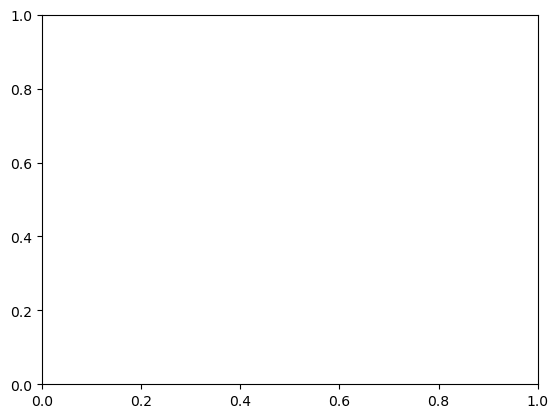

In [ ]:
plt.plot(S)

## High Pass

In [ ]:
def filter_hp(bf, fsam, f, nrebound):

    #subtract continuous componen
    bf  = bf -  np.mean(bf, axis=2, keepdims=True)
    #butterworth high-pass filter
    b, a = butter(3, f*0.6, 'highpass', output='ba', fs=fsam)
    #apply filter along the time dimension
    bff = lfilter(b, a, bf, axis=2)
    #the first nelim images are eliminated because the filter border effect
    if nrebound > 0:
        bff[:,:,0:nrebound] = 0
        
    return bff

Beamformed data of shape (307, 256) saved at: ./data_filtered/phantom_test/filtered_bf/0001_bff_hp.npy


/tmp/ipykernel_5662/3607415195.py:2: RuntimeWarning: invalid value encountered in divide
  plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp),axis=2) / np.max(np.sum(np.abs(filtered_hp),axis=2))), aspect='auto', cmap='viridis')


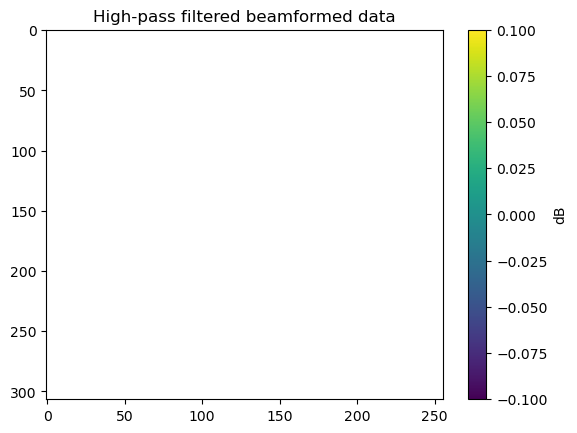

In [ ]:
filtered_hp = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 1)
plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp),axis=2) / np.max(np.sum(np.abs(filtered_hp),axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.title('High-pass filtered beamformed data')

if save_data:
    save_beamformed_data(np.sum(filtered_hp, axis=2), f"{beamformed_filtered_matrix_name}_hp", f"{bf_data_path}{folder_name}/filtered_bf/")

if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp.png")
    
plt.show()

## HP + SVD

/tmp/ipykernel_5662/2945908616.py:4: RuntimeWarning: invalid value encountered in divide
  plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis')


Beamformed data of shape (307, 256) saved at: ./data_filtered/phantom_test/filtered_bf/0001_bff_hp_svd.npy


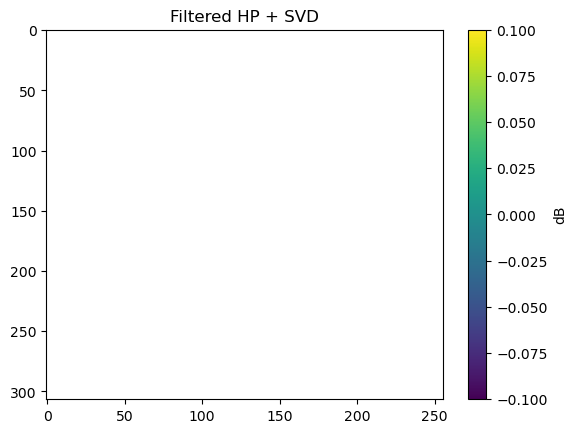

In [ ]:
filtered_hp_svd = filter_hp(bf_matrix, sampling_rate, params["rf"]["frequency"], 0)
filtered_hp_svd, S = filter_svd(filtered_hp_svd, 12)

plt.imshow(20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2))), aspect='auto', cmap='viridis')
plt.colorbar(label='dB')
plt.title(f"Filtered HP + SVD")

if save_data:
    save_beamformed_data(np.sum(filtered_hp_svd, axis=2), f"{beamformed_filtered_matrix_name}_hp_svd", f"{bf_data_path}{folder_name}/filtered_bf/")

if save_image:
    plt.savefig(f"{bf_data_path}{folder_name}/images/{beamformed_filtered_matrix_name}_hp_svd.png")

plt.show()

# Benchmark results

In [ ]:
matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))

/tmp/ipykernel_5662/4220865196.py:1: RuntimeWarning: invalid value encountered in divide
  matrix_to_analyze = 20 * np.log10(np.sum(np.abs(filtered_hp_svd),axis=2) / np.max(np.sum(np.abs(filtered_hp_svd), axis=2)))


Signal: nan dB, Noise: nan dB, SNR: nan dB


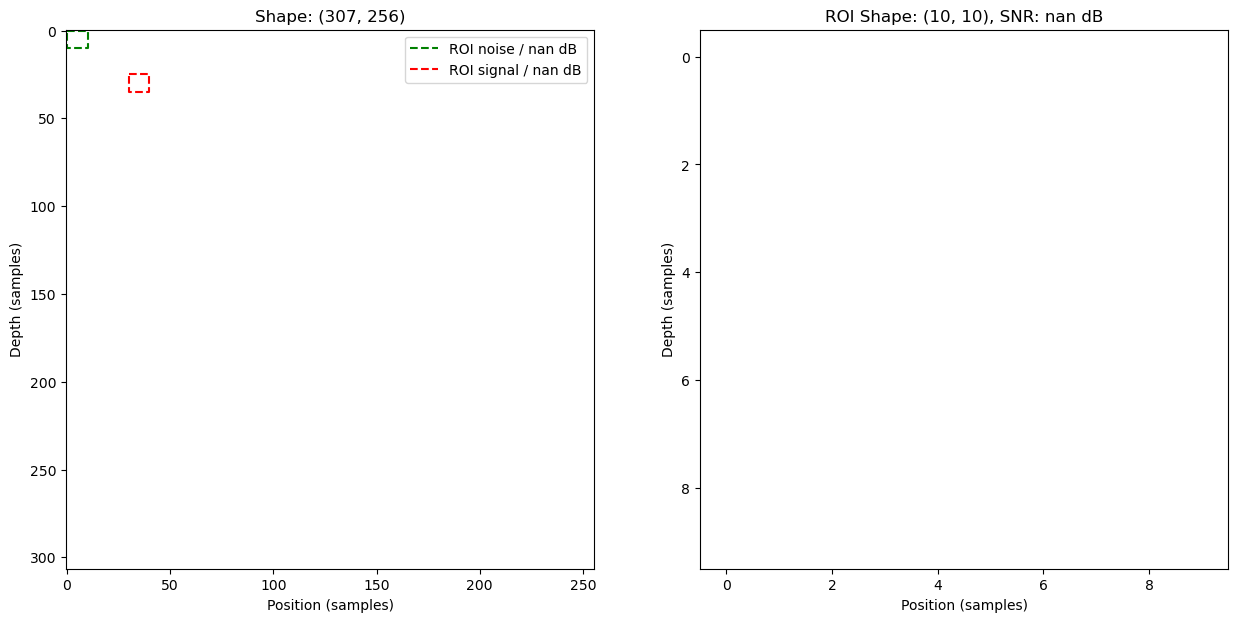

In [ ]:
x0 = 30
z0 = 25
nx = 10
nz = 10

sub_plot_size = 1 if nx == None or nz == None else 2

fig, ax = plt.subplots(1, sub_plot_size, figsize=(15, 7))

if sub_plot_size == 1:
    ax = [ax]

#define noise region of interest
noise_matrix = matrix_to_analyze[0:0+nz, 0:0+nx]
Pnoise = np.mean(noise_matrix)
ax[0].plot([0, 0+nx, 0+nx, 0, 0], [0, 0, 0+nz, 0+nz, 0], 'g--', label=f'ROI noise / {Pnoise:.2f} dB')


ax[0].imshow(matrix_to_analyze, aspect='auto', cmap='viridis')
ax[0].set_xlabel("Position (samples)")
ax[0].set_ylabel("Depth (samples)")
ax[0].set_title(f"Shape: {matrix_to_analyze.shape}")

data = matrix_to_analyze[z0:z0+nz, x0:x0+nx]
Psignal= np.mean(data)

ax[0].plot([x0, x0+nx, x0+nx, x0, x0], [z0, z0, z0+nz, z0+nz, z0], 'r--', label=f'ROI signal / {Psignal:.2f} dB')
ax[0].legend()

ax[1].imshow(data, aspect='auto', cmap='viridis')
ax[1].set_xlabel("Position (samples)")
ax[1].set_ylabel("Depth (samples)")

snr_db = Psignal - Pnoise

ax[1].set_title(f"ROI Shape: {data.shape}, SNR: {snr_db:.2f} dB")

print(f"Signal: {Psignal:.2f} dB, Noise: {Pnoise:.2f} dB, SNR: {snr_db:.2f} dB")

plt.show()

In [ ]:
if save_data:
    save_beamformed_data(np.sum(filtered_hp_svd, axis=2), beamformed_filtered_matrix_name, destination=bf_data_path + folder_name + "/filtered_bf/")

Beamformed data of shape (307, 256) saved at: ./data_filtered/phantom_test/filtered_bf/0001_bff.npy
